# Day 1 · The letrozole cohort, and why a bag of codes fails

**Today's goal, in one sentence:** show a real example of two patients who look *completely identical* to a computer but are medically opposite cases — and use that to explain why the simplest way of describing a patient (a checklist of "does the patient have code X: yes/no") throws away exactly the information a good model would need.

**The problem.** Letrozole is prescribed for two unrelated reasons: as first-line ovulation induction for infertility, or as adjuvant aromatase-inhibitor therapy after breast cancer treatment. A bare drug-exposure code doesn't say which — the same molecule, the same claim shape, opposite clinical meaning.

*In plain terms: if all you know is "this patient was given letrozole," you cannot tell whether they're trying to get pregnant or recovering from cancer treatment. The drug code alone is silent on the reason it was prescribed.*

**The cohort**, from `sql/breast_cancer_cohort.sql`: every (female) patient with a breast cancer diagnosis (ICD9 174.x / ICD10 C50.x / the matching SNOMED standard concept). This is the diagnosis side of the ambiguity, analogous to dx_9487's R07.x codes in the chest-pain cohort — the drug's *reason* is what's actually ambiguous, not the diagnosis itself.

**The working hypothesis** (to test, not assume): most letrozole use in this cohort is oncology-driven, since the cohort is anchored on a breast cancer diagnosis. A fertility-labelled subgroup showing up at all would be a genuine finding worth explaining (e.g. a patient who later develops breast cancer after an earlier fertility treatment), not something the cohort construction should manufacture by itself.

**Today's sub-goals:** get the OMOP extract for this cohort loaded as one event stream, understand the four preprocessing decisions baked into it, and see the exact failure that motivates the rest of the week.

### Summary

Every unsupervised method is a distance function plus a search procedure. Changing the
representation moves the answer more than changing the algorithm does, so the leverage is
upstream. Today is the upstream.

*In plain terms: "representation" just means how we turn a patient's messy history of visits, diagnoses, and prescriptions into rows and columns a computer can compare. Get that step wrong, and no amount of clever math afterward can fix it — the information is simply gone by the time the algorithm sees it. That's why today is entirely about that first step, before any modeling happens.*

### Three things that all get called "pattern"

*People use the word "pattern" loosely, for at least three different things. This table pins those down, so when someone says "we found a pattern," you know which of the three they mean and how much to trust it.*

| Term | What it is | Built on | Auditable? |
|---|---|---|---|
| **Cluster** | a group of similar patients | Day 2 | partly |
| **Motif** | a recurring *ordered* subsequence | Day 3 | yes |
| **Embedding** | a direction in a learned space | Day 4 | no |

Motifs are the current best deliverable for this project

### Technique chosen per subtopic

*For each question below, several statistical tools could answer it. This is the one this course uses, and why — the alternatives are listed too, in case a stakeholder asks "why not X."*

| Subtopic | We use | Mentioned only |
|---|---|---|
| Similarity | **cosine** on binary codes | Jaccard, Dice, Gower, Mahalanobis |
| Linear reduction | **truncated SVD** | PCA (same thing, dense), ICA, factor analysis |
| Parts-based | **NMF** | archetypal analysis, sparse PCA |
| Non-linear view | **t-SNE** (ships with sklearn) | UMAP — better, `pip install umap-learn` |

## 0 · Getting the data

**Goal:** pull every breast-cancer patient's medical history out of the data warehouse and save it to disk as plain files, so the rest of the notebook runs offline and reproducibly, without hitting Snowflake every time.

`ethos_omop.extract_cohort()` pulls the breast-cancer cohort: any female patient carrying a breast cancer diagnosis, defined in `sql/breast_cancer_cohort.sql`. It dumps the same shape `extract_omop()` does — `master_*` as the source of truth, `ethos_dip` excluded on both `concept_id` and `source_concept_id` for every domain table, standard-named symlinks for `meds_etl_omop`, plus:

* **`concept.csv` slimmed** to the concept_ids the cohort actually references, instead of the full multi-million-row table.
* **`concept_ancestor` dumped too**, restricted to rows touching the cohort — needed for ontology rollup (drug products to ingredients, unspecified diagnoses to their parents).

*In plain terms: this is a one-time data export, like running a big report and saving the results as spreadsheets (CSV files) in a folder. Every cell below reads from that folder, not from Snowflake directly.*

```python
import ethos_omop as eo
eo.extract_cohort("../sql/breast_cancer_cohort.sql")   # -> ../inputs/breast_cancer_cohort/
```

The next cell runs this once and skips it on every re-run once `../inputs/breast_cancer_cohort/` exists.

**No Snowflake access, or want to see the notebook run against data whose right answer you already know?** Use the synthetic demo extract instead:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through `concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is the whole problem this course is about, and every notebook here works either way.

In [1]:
# One-time export from Snowflake into local CSV files. Safe to re-run: it
# checks OUT_DIR first and skips the (slow) Snowflake pull if the files are
# already there, so you won't accidentally re-download everything every time
# you restart the notebook.
import os
import ethos_omop as eo

OUT_DIR     = "../../inputs/breast_cancer_cohort/"      # extract_cohort() output, relative to this notebook's dir
COHORT_SQL  = "../../sql/breast_cancer_cohort.sql"     # relative to this notebook's cwd

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")


../../inputs/breast_cancer_cohort// already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.


In [2]:
# Load everything from disk into memory as one big table of "events":
# one row per visit / diagnosis / procedure / drug / lab result, for every
# patient in the cohort. `codesets` translates raw medical codes into the
# readable clinical labels (letrozole, breast_cancer, mastectomy, ...) used
# throughout the rest of the notebook.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
events   = eo.tag_events(eo.load_events(OUT_DIR, domains=DOMAINS), codesets)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

print(f"events {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)

events (886843, 11)   patients 1514
codeset coverage: 7.7% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,tag,in_codeset
0,1328,581477,2019-05-01,Visit,Visit,OMOP4822458,Office Visit,Visit,Visit/OMOP4822458,office_visit__visit__581477,False
1,1328,193322,2019-05-01,Condition,SNOMED,301754002,Right lower quadrant pain,Clinical Finding,SNOMED/301754002,right_lower_quadrant__clinical_finding__193322,False
2,1328,436070,2019-05-01,Condition,SNOMED,34713006,Vitamin D deficiency,Disorder,SNOMED/34713006,vitamin_d_deficiency__disorder__436070,False
3,1328,37108742,2019-05-01,Measurement,SNOMED,119971000119104,C-reactive protein above reference range,Clinical Finding,SNOMED/119971000119104,creactive_protein_ab__clinical_finding__37108742,False
4,1328,440448,2019-05-02,Condition,SNOMED,74400008,Appendicitis,Disorder,SNOMED/74400008,appendicitis__disorder__440448,False
5,1328,2514403,2019-05-02,Procedure,CPT4,99220,"Initial observation care, per day, for the eva...",CPT4,CPT4/99220,initial_observation___cpt4__2514403,False


In [3]:
# Sanity check: how big is what we just loaded? Useful to know before you
# wait on a slow cell later, and a quick way to notice if an extract came
# back suspiciously empty or huge.
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file   rows   MB
           concept_ancestor.csv 383446  8.4
master_condition_occurrence.csv 273106 40.1
    master_visit_occurrence.csv 270575 33.8
master_procedure_occurrence.csv 197093 29.2
         master_observation.csv 148150 18.3
         master_measurement.csv 130340 17.7
       master_drug_exposure.csv 120874 23.1
                    concept.csv  10348  1.3
                     person.csv   1514  0.2
                      death.csv      0  0.0


## 1 · Four decisions already made for you

**Goal:** flag four judgment calls baked into the data-loading step above, before you trust any number that comes out of it. None of these are bugs — they're modelling choices someone had to make, and you should know what they are.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

*In plain terms: medical coding systems (ICD, SNOMED, etc.) have multiple ways to say the same thing. "Standard concepts" is OMOP's canonical, de-duplicated version of each code — we only keep those, so the same diagnosis isn't double-counted under two different code spellings.*

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

*In plain terms: some medical codes look like numbers (e.g. `"0042"`) but aren't meant to be treated as one — turning them into an actual number silently drops the leading zero and corrupts the code.*

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

*In plain terms: claims data tells you "something happened on March 3rd," not "at 2:14pm." If five things happened the same day, we can't know their real order — so we pick one consistent order and are upfront that it's a guess, rather than pretending we have more precision than we do.*

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

*In plain terms: we only see what's in this data source. "This patient has no record of diabetes" might mean they truly don't have it, or it might just mean we started watching them too late to see it. Absence of a code is not proof of absence of the condition.*

count    1514.0
mean     2186.0
std       488.0
min        12.0
25%      2063.0
50%      2398.0
75%      2503.0
max      3010.0


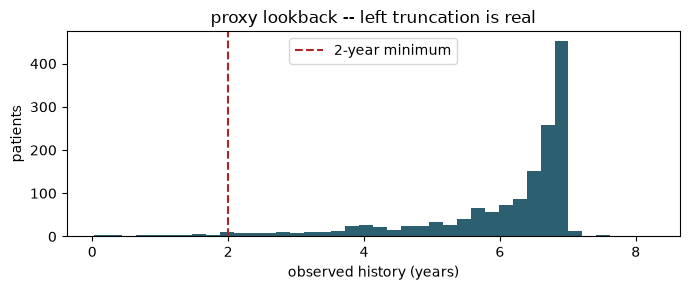


35 patients (2.3%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [4]:
# How much history do we actually have per patient? (See point 4 above --
# this is the proxy lookback window, not a true observation period.) The
# 2-year line is a common minimum bar for "long enough history to trust an
# absence of a code."
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

**Goal:** show how a clinical concept like "letrozole" turns into an actual, checkable list of medical codes — and why we resolve it by *name* instead of hand-typing code numbers.

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

*In plain terms: instead of writing down a fixed list of magic numbers ("code 19022830 means letrozole"), we write down a search pattern ("anything whose name matches 'letrozole' in the RxNorm vocabulary") and let the computer look up the matching codes every time. That way the same notebook keeps working even if the underlying code numbers differ between data sources.*

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

In [5]:
# Eyeball it: what did the "breast_cancer" pattern actually match? Several
# rows here -- one per matching SNOMED concept -- exactly what you want to
# see before trusting anything downstream. Read straight from codesets.yaml
# (via eo.CODESETS) instead of retyping the patterns here, so this can't
# silently drift from what build_codesets() actually resolves.
bc_spec = eo.CODESETS['breast_cancer']
eo.resolve(concept, bc_spec['patterns'], vocabularies=bc_spec.get('vocabularies'))

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
6722,4179963,Family history of breast cancer,SNOMED,429740004,Observation
8773,1075590,Primary inflammatory carcinoma of breast,SNOMED,1306512006,Condition
6381,4162253,Primary malignant neoplasm of breast,SNOMED,372137005,Condition
10102,4147961,Screening for malignant neoplasm of breast,SNOMED,268547008,Measurement


In [6]:
# Medical coding systems are hierarchical: a drug "ingredient" (letrozole)
# can have several branded/dosed "products" under it, and a diagnosis can
# have several more specific children. `concept_ancestor` lets us walk that
# hierarchy in either direction.

# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
lz = codesets['letrozole']
print("letrozole concepts, direct:      ", len(lz))
print("letrozole concepts, + descendants:", len(eo.expand_descendants(lz)))

# And roll an unspecified diagnosis UP to its parents -- directly useful for the
# unspecified breast-cancer codes this whole cohort is built from.
bc = codesets['breast_cancer']
print("breast cancer parents, 1 level up:  ", len(eo.roll_up(bc, levels=1)))

letrozole concepts, direct:       1
letrozole concepts, + descendants: 1
breast cancer parents, 1 level up:   2


In [7]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
# What are the most common tags overall, and what fraction of all events
# actually got one of our curated labels versus falling back to a raw name?
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
pharmacy__visit__38004338                   90887
office_visit__visit__581477                 68519
receptor_assay                              12347
venipuncture_for_blo__procedure__4102442    11009
complete_blood_count__procedure__4319466     9644
breast_cancer                                9612
comprehensive_metabo__procedure__3661905     9387
therapeutic_procedur__cpt4__2314284          8240
essential_hypertensi__disorder__320128       8023
manual_therapy_techn__cpt4__2314290          7584
primary_malignant_ne__disorder__4187850      6360
radiation_therapy                            5680
telehealth__visit__722455                    5606
chemotherapy                                 5203
bone_health                                  4888

tagged into a codeset: 7.7%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

*In plain terms: we only defined clinical labels (letrozole, mastectomy, breast_cancer, ...) for the codes relevant to this specific question. Everything else in a patient's record still exists in the data, we just haven't given it a friendly name -- it isn't lost, and it's part of what later, more automated methods (Day 4's embeddings) can pick up on that our hand-picked labels can't.*

## 3 · The bag of codes, and the exact failure

**Goal for this section:** build the simplest possible patient representation — a checklist of which codes each patient has — and then show exactly where it breaks.

In [8]:
# The "bag of codes": one row per patient, one column per code, 1 if the
# patient ever had that code and 0 if not. This throws away *when* things
# happened and *how many times* -- it's the simplest representation there
# is, and the one we're about to show fails.
X = eo.bag_of_codes(events, min_count=20)
print(X.shape)
X.iloc[:5, :8]

(1514, 3010)


tag,025_mg_05_mg_dose_15__branded_drug__793152,025_mg_05_mg_dose_3___branded_drug__741834,03_ml_sarscov2_covid__quant_branded_drug__1735839,03_ml_sarscov2_covid__quant_branded_drug__747830,03_ml_sarscov2_covid__quant_clinical_drug__747831,04_ml_adalimumab_100__quant_branded_drug__1592710,04_ml_cyclosporine_0__quant_branded_drug__702619,04_ml_enoxaparin_sod__quant_clinical_drug__40160973
person_id,,,,,,,,
1328,0,0,0,0,0,0,0,0
7274,0,0,0,0,0,0,0,0
9539,0,0,0,0,0,0,0,0
9710,0,0,0,0,0,0,0,0
11141,0,0,0,1,0,0,0,0


**Goal:** get a feel for `X` before we do anything clever with it — which codes are common, which are rare, and how that's different from what an NMF component (two sections down) will tell us.

Prevalence read directly off `X`, before any factorization -- contrasted with the NMF-loading readout two sections down. A loading tells you what's characteristic of a *component*, not how common a code is overall: `breast_cancer` is ~100% prevalent here yet won't dominate any single NMF component once it's dropped as near-constant.

*In plain terms: "prevalence" here just means "what % of patients have this code at all." That's a different question from "which codes define this cluster/component" -- a code can be common across the whole cohort (like `breast_cancer`, since that's how the cohort was defined) without being distinctive of any particular subgroup.*

3010 codes, prevalence range 0.066% - 83.157%


,prevalence
tag,
office_visit__visit__581477,83.2%
breast_cancer,78.8%
venipuncture_for_blo__procedure__4102442,77.5%
comprehensive_metabo__procedure__3661905,72.9%
complete_blood_count__procedure__4319466,72.8%
lipid_panel_this_pan__cpt4__2212095,62.4%
level_iv_surgical_pa__cpt4__2213283,62.3%
receptor_assay,62.2%
bone_health,60.8%


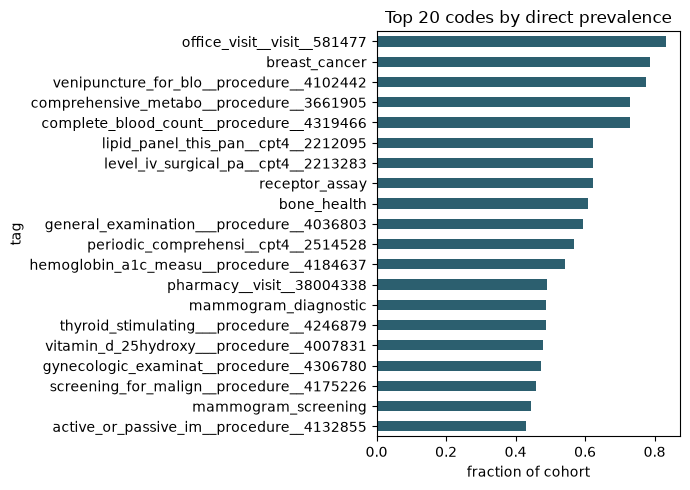

In [9]:
# How common is each code across the whole cohort? (Just column-wise
# averages of the 0/1 matrix above -- no modelling yet.)
prevalence = X.mean().sort_values(ascending=False)
print(f"{len(prevalence)} codes, prevalence range "
      f"{prevalence.min():.3%} - {prevalence.max():.3%}")
display(prevalence.head(20).to_frame('prevalence').style.format('{:.1%}'))

plt.figure(figsize=(7, 5))
prevalence.head(20).iloc[::-1].plot.barh(color='#2C5F6F')
plt.xlabel('fraction of cohort'); plt.title('Top 20 codes by direct prevalence')
plt.tight_layout(); plt.show()

In [10]:
# The punchline of the whole notebook: find one letrozole+breast_cancer
# patient labelled "fertility" and one labelled "oncology" by the rule-based
# check below, then show that the bag-of-codes view (X) can't tell them
# apart at all, even though their real timelines obviously can.
weak = eo.weak_labels(events)                      # rule-based probe labels
lab  = weak.set_index('person_id').weak_label

both = [p for p in X.index
        if X.loc[p].get('letrozole', 0) == 1
        and X.loc[p].get('breast_cancer', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'fertility'), None)
b = next((p for p in both if lab[p] == 'oncology'),  None)
assert a and b, ("No identical-bag pair found in this sample. Increase the extract "
                 "size, or inspect `both` to see which side is missing.")

# Same view, plus a few randomly-picked columns where they DO differ -- shown
# side by side so it's clear these two patients aren't identical everywhere,
# just on the two columns that matter for the fertility-vs-oncology question.
diff_cols_all = X.columns[X.loc[a] != X.loc[b]]
diff_cols = list(pd.Index(diff_cols_all).to_series()
                  .sample(n=min(3, len(diff_cols_all)), random_state=0))
print("bag-of-codes view -- identical on letrozole/breast_cancer, "
      f"differs on {diff_cols}:")
display(X.loc[[a, b], ['letrozole', 'breast_cancer'] + diff_cols])

print("\nactual timelines -- obviously different:")
# FOCUS = eo.FERTILITY_TAGS / eo.ONCOLOGY_TAGS -- the same constants
# weak_labels() used to build `lab` -- plus the exposure/anchor tags, so this
# timeline shows the full evidence base behind the label instead of a
# hand-picked subset that can drift from it. Tags that never occurred for a
# given patient simply produce no row below, so this costs nothing visually.
FOCUS = ['letrozole', 'breast_cancer'] + eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS
for pid in (a, b):
    s = events[(events.person_id == pid) & events.tag.isin(FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'tag']].drop_duplicates('tag').to_string(index=False))

letrozole patients: 70   labelled: 22   both-evidence (dropped): 35   no-evidence (dropped): 13
bag-of-codes view -- identical on letrozole/breast_cancer, differs on ['electrocardiogram_ro__cpt4__2313816', 'lisinopril_10_mg_ora__clinical_drug__19080128', 'acetaminophen_500_mg__clinical_drug__19020053']:


tag,letrozole,breast_cancer,electrocardiogram_ro__cpt4__2313816,lisinopril_10_mg_ora__clinical_drug__19080128,acetaminophen_500_mg__clinical_drug__19020053
person_id,,,,,
4460222,1,1,0,1,1
308016,1,1,1,0,0



actual timelines -- obviously different:

  person_id 4460222  (fertility)
event_date            tag
2021-04-22 pregnancy_test
2025-06-21      letrozole
2026-07-24  breast_cancer

  person_id 308016  (oncology)
event_date                  tag
2022-02-08       receptor_assay
2023-06-08        breast_cancer
2023-06-08 lymph_node_procedure
2023-06-08           mastectomy
2024-03-04            letrozole


**That is the motivation for the whole week.** Identical features, opposite risk. The
information lives in the order, and the representation threw it away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

*In plain terms: this isn't a case of "use a fancier algorithm and it'll figure it out." The bag-of-codes table literally does not contain the information needed to tell these two patients apart -- both rows are 1, 1. No amount of machine learning can pull a distinction out of data where the distinction was never recorded in the first place. You have to fix the representation, not the model.*

### On `weak_labels()`

**Goal:** since there's no ground-truth "this patient took letrozole for fertility / for cancer" label in claims data, build a trustworthy *stand-in* label we can use to check our work — and be upfront about how it's built and where it can go wrong.

There are no adjudicated labels in claims data. `weak_labels()` builds probe labels for the
letrozole indication from **corroborating co-evidence only** — clomiphene, gonadotropins and
infertility diagnoses on one side; mastectomy, biopsy, tamoxifen and anastrozole on the
other. Patients with both kinds of evidence, or neither, are dropped, and the counts are
printed so you can see how many.

*In plain terms: instead of guessing the reason for letrozole directly, we look for other, more specific evidence nearby — did the patient also have a fertility drug or an infertility diagnosis? Did they also have a mastectomy or a cancer drug? If the evidence points clearly one way, we use that as the label. If it points both ways, or neither way, we honestly say "we don't know" and drop them rather than force a guess.*

**The time delta is deliberately not used.** If you label by "drug before diagnosis" and
then test whether the time delta predicts the label, you get perfect accuracy by
construction and have learned nothing. These labels are for evaluation, never features.

*In plain terms: it would be tempting to say "letrozole came before the cancer diagnosis, so it must be fertility-related." But that's using the very thing we're trying to test (timing) to build the answer key -- then "discovering" that timing predicts the answer would be circular, not a real finding. So the answer key is built from a different, independent kind of evidence, and timing is only used afterward to see if it can predict that answer.*

## 4 · Distance metrics disagree

**Goal:** show that "how similar are two patients" isn't one universal number — the metric you pick changes the answer, and picking the wrong one for claims data quietly breaks everything downstream.

In [11]:
from sklearn.metrics import pairwise_distances

# breast_cancer is the cohort anchor -- ~100% prevalence here, so it's a near-
# constant column that carries no discriminative signal and would just eat a
# component. Drop it before any distance/SVD/NMF fit; X itself (with the
# column) stays untouched for the two-patient demo above.
X_nmf = X.drop(columns=['breast_cancer'])
Xv  = X_nmf.values.astype(float)

# First: pick 400 random patients and measure how "far apart" every pair is,
# under two different definitions of distance. If cosine and jaccard disagree
# on how spread out the cohort is, that's a sign the metric matters, not just
# the data.
sub = Xv[:400]
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

# Second: for one specific patient (`a`, our fertility case from the demo
# above), who are their 5 nearest neighbours under each metric, and what
# weak label do those neighbours carry?
pos = list(X.index).index(a)
print()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(Xv[pos:pos+1], Xv, metric=m)[0]
    nn = [X.index[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")

cosine     mean=0.834  sd=0.077
jaccard    mean=0.916  sd=0.047

cosine     neighbours of 4460222: ['?', '?', '?', '?', '?']
jaccard    neighbours of 4460222: ['?', '?', '?', '?', '?']


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

*In plain terms: a patient with 200 recorded codes isn't automatically "less similar" to everyone else than a patient with 20 codes — but a naive distance metric (Euclidean) treats it that way, because it's sensitive to how many codes are turned on, not just which ones. Cosine distance cares about the pattern of codes, not the raw count, which is what we actually want to compare.*

## 5 · The curse of dimensionality

**Goal:** show why "just add more codes" eventually backfires — past a certain number of columns, distance stops being meaningful at all.

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

*In plain terms: with only a handful of columns, "similar" and "different" are easy to tell apart. Once you have tens of thousands of columns and each patient only has a handful of them turned on, almost every pair of patients ends up looking roughly equally (dis)similar to each other -- there's no longer a meaningful "close" versus "far." This is a general math fact (the "curse of dimensionality"), not something specific to our data.*

In [12]:
# Not our data -- pure demonstration. Make random sparse 0/1 tables (2% of
# cells "on", like real code data) of increasing width, and watch the ratio
# of the closest pair's distance to the farthest pair's distance collapse
# toward 1 as width grows. That's the curse of dimensionality happening in
# front of you, independent of anything about breast cancer or letrozole.
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

  dims   min/max distance ratio
    10                    0.000
    50                    0.000
   200                    0.000
  1000                    0.568
  5000                    0.782

Ratio -> 1 means every patient is equally far from every other.


## 6 · Truncated SVD and NMF

**Goal:** compress thousands of sparse code columns down into a handful of numbers per patient that are actually usable for distance/clustering/visualization — and see two different ways of doing that compression.

*In plain terms: both methods below take the wide, sparse `X` table (thousands of mostly-zero columns) and produce a much narrower table (a few dozen columns) that still captures most of the real signal. Think of it as automatic summarization of a patient's code history into a small number of "themes." SVD and NMF differ in what kind of themes they're allowed to produce -- that difference is exactly why we look at both.*

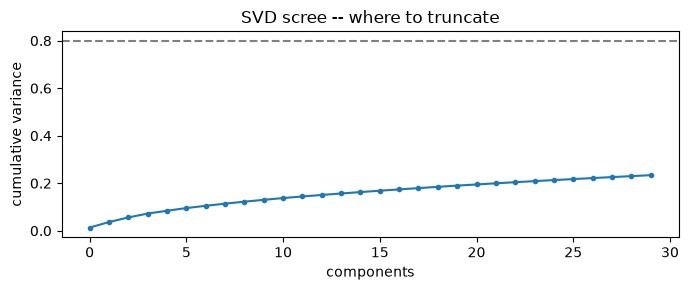

In [13]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize

# SVD finds the directions that explain the most variation in the data --
# similar in spirit to PCA. Its components can be positive or negative and
# don't have a clean "these codes belong to this theme" reading, but they're
# a solid general-purpose compression. Normalize first so this lines up with
# the cosine geometry we already decided was the right one for this data.
Xn  = normalize(Xv)                                  # cosine geometry, done properly
svd = TruncatedSVD(n_components=min(30, Xv.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)

# How many components until we've captured most of the signal? The scree
# plot below answers that -- steep rise then flattening out means most of
# what matters is in the first handful of components.
plt.figure(figsize=(7, 3))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.8, ls='--', c='grey')
plt.xlabel('components'); plt.ylabel('cumulative variance')
plt.title('SVD scree -- where to truncate'); plt.tight_layout(); plt.show()

### Choosing k for the NMF

The k above was chosen by reading the components. This sweep adds numbers for it, the
NMF counterpart of Day 2's elbow + silhouette + bootstrap-ARI table for KMeans.

*In plain terms: fit the NMF at several values of k and, for each one, check how well it
explains patients it was never fit on, how well separated the resulting patient groups are
(silhouette), and whether the same bundles come back on re-draws. Then pick a k where adding
more components stops paying for itself but the bundles are still reproducible.*

Every k is fit on the same `N_SWEEP` training patients and scored on a disjoint `N_HELD`
held-out set, so the comparison is fair and the error is not just training fit. The
silhouette is computed in the SVD space (`Z`) that Day 2 used for KMeans, not in NMF's own
loading space, which would be circular because those loadings defined the groups.

The whole sweep is repeated on every split in `SPLIT_SEEDS` (independent random train / held-out
splits of the cohort), each with `N_BOOT_K` bootstrap refits per k. More refits only sharpen the
estimate within one split. A second split shows whether a k looks stable only because of the
patients it happened to see. Every NMF fit in this section uses the same settings (`NMF_KW`,
defined in the stability cell), so the base fit and its refits are converged the same way.

In [14]:
import time
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

# one place for the NMF fit settings, used by every NMF fit in this section
NMF_KW = dict(init='nndsvd', random_state=0, max_iter=2000, tol=1e-4)

N_BOOT        = 10        # refits; each is a full NMF fit, raise once you know the runtime
N_BOOT_SAMPLE = 20_000    # patients per resample (capped at the cohort size)
N_EVAL        = 20_000    # fixed patients used to compare argmax labels (capped)

def _unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

def nmf_stability(nmf_base, Xv, n_boot=N_BOOT, n_sample=N_BOOT_SAMPLE,
                  n_eval=N_EVAL, seed=0):
    """Bootstrap-refit NMF; return per-component matched cosine and per-boot ARI.

    Component order is arbitrary between fits (label switching), so each refit's
    components are matched to the base fit's by cosine similarity (Hungarian
    algorithm). ARI compares argmax patient partitions, which needs no matching.
    """
    k    = nmf_base.n_components_
    Hb   = _unit(nmf_base.components_)
    rng  = np.random.default_rng(seed)
    ev   = rng.choice(len(Xv), min(n_eval, len(Xv)), replace=False)
    lab0 = nmf_base.transform(Xv[ev]).argmax(1)
    cos, ari = [], []
    for b in range(n_boot):
        t0  = time.perf_counter()
        idx = rng.choice(len(Xv), min(n_sample, len(Xv)), replace=True)
        m   = NMF(n_components=k, **NMF_KW).fit(Xv[idx])
        S        = Hb @ _unit(m.components_).T         # base x refit cosine
        rows, cols = linear_sum_assignment(-S)          # rows come back sorted 0..k-1
        cos.append(S[rows, cols])                       # cos[b][j] = base component j
        ari.append(adjusted_rand_score(lab0, m.transform(Xv[ev]).argmax(1)))
        print(f"  boot {b + 1}/{n_boot}  {time.perf_counter() - t0:.0f}s  "
              f"ARI {ari[-1]:.3f}")
    return np.array(cos), np.array(ari)


split 1  k=3   done in 2s
split 1  k=4   done in 2s
split 1  k=5   done in 2s
split 1  k=6   done in 3s
split 1  k=7   done in 3s
split 1  k=8   done in 2s
split 1  k=9   done in 3s
split 1  k=10  done in 3s
split 1  k=11  done in 3s
split 1  k=12  done in 3s
split 1  k=13  done in 3s
split 1  k=14  done in 4s
split 2  k=3   done in 3s
split 2  k=4   done in 1s
split 2  k=5   done in 2s
split 2  k=6   done in 3s
split 2  k=7   done in 3s
split 2  k=8   done in 3s
split 2  k=9   done in 2s
split 2  k=10  done in 4s
split 2  k=11  done in 3s
split 2  k=12  done in 3s
split 2  k=13  done in 5s
split 2  k=14  done in 4s
split 3  k=3   done in 2s
split 3  k=4   done in 2s
split 3  k=5   done in 2s
split 3  k=6   done in 2s
split 3  k=7   done in 3s
split 3  k=8   done in 3s
split 3  k=9   done in 2s
split 3  k=10  done in 3s
split 3  k=11  done in 3s
split 3  k=12  done in 4s
split 3  k=13  done in 5s
split 3  k=14  done in 4s
split 4  k=3   done in 2s
split 4  k=4   done in 2s
split 4  k=5

,held_out_err,silhouette,ari_split1,ari_split2,ari_split3,ari_split4,ari_split5,ari_min,cos_mean,n_unstable,n_used
k,,,,,,,,,,,
3,0.871,0.071,0.629,0.470,0.566,0.599,0.623,0.470,0.953,0,3
4,0.865,0.062,0.762,0.824,0.839,0.785,0.747,0.747,0.970,0,4
5,0.861,0.054,0.554,0.535,0.639,0.598,0.543,0.535,0.889,2,5
6,0.857,0.050,0.539,0.622,0.518,0.542,0.490,0.490,0.845,2,6
7,0.853,0.047,0.535,0.634,0.617,0.520,0.517,0.517,0.855,3,7
8,0.851,0.043,0.573,0.461,0.499,0.505,0.462,0.461,0.817,2,8
9,0.848,0.039,0.490,0.471,0.531,0.509,0.533,0.471,0.805,4,9
10,0.846,0.040,0.478,0.445,0.466,0.446,0.449,0.445,0.777,4,10
11,0.843,0.033,0.475,0.398,0.464,0.429,0.461,0.398,0.756,6,11


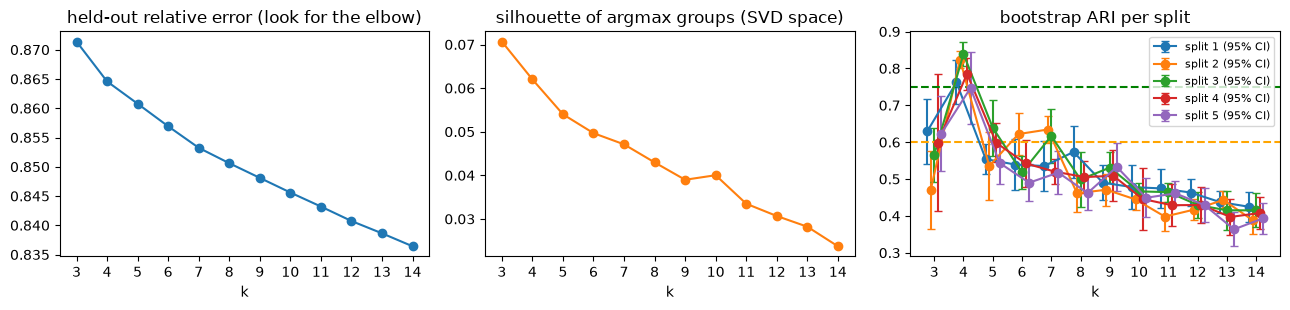

largest k with ARI >= 0.60 on every split and mean cos >= 0.75: 4
largest k with ARI >= 0.75 on every split and no unstable component: none


In [15]:
import time
import io, contextlib
from sklearn.metrics import silhouette_score
from scipy import stats

K_GRID      = list(range(3, 15))
SPLIT_SEEDS = (1, 2,3,4,5)      # independent train / held-out splits of the cohort
N_SWEEP     = min(20_000, int(0.6 * len(Xv)))   # train patients every k is fit on (scales with the cohort)
N_HELD      = min(10_000, len(Xv) - N_SWEEP)    # disjoint held-out patients for error / silhouette
N_BOOT_K    = 10          # bootstrap refits per k and split (reuses nmf_stability above)
NC_SIL      = min(24, Z.shape[1])   # SVD dims Day 2 scored KMeans silhouette in

def nmf_k_sweep(k_grid, n_boot, split_seed):
    """Per-k metrics on one train / held-out split drawn with split_seed."""
    perm   = np.random.default_rng(split_seed).permutation(len(Xv))
    tr, ho = perm[:N_SWEEP], perm[N_SWEEP:N_SWEEP + N_HELD]
    Xtr, Xho, Zho = Xv[tr], Xv[ho], Z[ho, :NC_SIL]      # Z rows align with Xv rows
    rows = []
    for k in k_grid:
        t0 = time.perf_counter()
        m  = NMF(n_components=k, **NMF_KW).fit(Xtr)
        Wh = m.transform(Xho)
        lab_ho = Wh.argmax(1)
        with contextlib.redirect_stdout(io.StringIO()):      # silence per-boot prints
            cos, ari = nmf_stability(m, Xtr, n_boot=n_boot, n_sample=len(Xtr),
                                     n_eval=len(Xtr), seed=k)
        share = np.bincount(lab_ho, minlength=k) / len(lab_ho)
        rows.append({'k': k,
                     'held_out_err': np.linalg.norm(Xho - Wh @ m.components_) / np.linalg.norm(Xho),
                     'silhouette': silhouette_score(Zho, lab_ho) if len(set(lab_ho)) > 1 else np.nan,
                     'ari_mean': ari.mean(), 'ari_sd': ari.std(ddof=1),
                     'ari_se': ari.std(ddof=1) / np.sqrt(n_boot),
                     'cos_mean': cos.mean(), 'n_unstable': int((cos.mean(0) < .75).sum()),
                     'n_used': int((share >= .01).sum())})
        print(f"split {split_seed}  k={k:<3} done in {time.perf_counter() - t0:.0f}s")
    return pd.DataFrame(rows).set_index('k')

per_split = {s: nmf_k_sweep(K_GRID, N_BOOT_K, s) for s in SPLIT_SEEDS}

# one row per k, summarised over splits (ari_min = the worst split)
g     = pd.concat(per_split, names=['split']).groupby('k')
sweep = pd.DataFrame({'held_out_err': g.held_out_err.mean(), 'silhouette': g.silhouette.mean(),
                      **{f'ari_split{s}': per_split[s].ari_mean for s in SPLIT_SEEDS},
                      'ari_min': g.ari_mean.min(), 'cos_mean': g.cos_mean.mean(),
                      'n_unstable': g.n_unstable.max(), 'n_used': g.n_used.min()})
display(sweep.round(3))

t_crit = stats.t.ppf(0.975, N_BOOT_K - 1)    # few refits -> t interval, not 1.96
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(sweep.index, sweep.held_out_err, marker='o')
ax[0].set_title('held-out relative error (look for the elbow)')
ax[1].plot(sweep.index, sweep.silhouette, marker='o', color='C1')
ax[1].set_title('silhouette of argmax groups (SVD space)')
for i, s in enumerate(SPLIT_SEEDS):                          # small x-offset so splits do not overlap
    d = per_split[s]
    ax[2].errorbar(d.index + (i - (len(SPLIT_SEEDS) - 1) / 2) * 0.12, d.ari_mean,
                   yerr=t_crit * d.ari_se, marker='o', capsize=3, label=f'split {s} (95% CI)')
ax[2].axhline(0.75, ls='--', c='green');  ax[2].axhline(0.60, ls='--', c='orange')
ax[2].set_title('bootstrap ARI per split'); ax[2].legend(fontsize=8)
for a in ax: a.set_xlabel('k'); a.set_xticks(sweep.index)
plt.tight_layout(); plt.show()

ok     = sweep[(sweep.ari_min >= .60) & (sweep.cos_mean >= .75)]
strong = sweep[(sweep.ari_min >= .75) & (sweep.n_unstable == 0)]
print("largest k with ARI >= 0.60 on every split and mean cos >= 0.75:",
      int(ok.index.max()) if len(ok) else "none")
print("largest k with ARI >= 0.75 on every split and no unstable component:",
      int(strong.index.max()) if len(strong) else "none")

### Reading the k sweep

- **Silhouette** is the KMeans-style number: how much closer each held-out patient is to
  their own `argmax` group than to the next nearest one, in the same SVD space Day 2 scored
  KMeans in. Closer to 1 is better. Expect it to be **low in absolute terms** (NMF groups are
  soft themes, not tight blobs) and to **fall as k grows**, so read the *shape*, not the
  level.
- **Held-out error** always falls as k grows, so the *elbow* is what matters, not the minimum.
- **ARI / cos** are the same bootstrap checks as above, now per k and per split. `ari_min` is
  the worst split, so a k only passes if it holds on every split. Stability usually decays as
  k rises; the largest k that still passes is an upper bound.
- **Same ranking on every split:** the pattern belongs to k, not to the patients drawn. Prefer
  the largest k with `ari_min` at or above 0.75. **Splits disagree, or neighbouring k overlap
  within their 95% intervals:** stability cannot separate them, so choose on clinical
  readability and keep the "suggestive" caveat on any k below 0.75.
- Compare k by the interval (`ari_se`), not by `ari_sd`. `ari_sd` is the spread across refits
  and does not shrink with more refits; `ari_se` does.
- **`n_used`** counts components that are the dominant component for at least 1% of held-out
  patients. A k where `n_used` stops growing is adding redundant or dead components.
- No single column picks k. A defensible k sits **after the error elbow and before stability
  collapses**, with a silhouette not much worse than its neighbours. The final check is still
  whether the extra components read as distinct clinical bundles, as in the component-reading discussion above.

### Are those components stable? Bootstrap validation of the NMF

Reading the top codes (above) checks whether a component *means* something. It does not
check whether the component would come back on a different sample of patients. This is the
NMF analogue of Day 2's KMeans bootstrap. It validates the last `nmf` fit above.

*In plain terms: re-run the NMF on random re-draws of the patients and see whether the same
code bundles show up. A bundle that keeps reappearing is real structure; one that only
appears for some draws is an accident of which patients were sampled.*

NMF component numbering is arbitrary between fits (component 3 in one run may be component 7
in the next), so each refit's components are first **matched** to the base fit's by cosine
similarity. Two outputs:

1. **Per component:** matched cosine between the base bundle and its refit counterpart.
2. **Cohort level:** ARI between the `argmax` patient labels, comparable with Day 2.

### Reading the stability table

- **`cos_mean` near 1** means the component's code bundle reappears almost unchanged in every
  resample. **Low `cos_mean` or high `cos_sd`** means the bundle depends on which patients
  happened to be drawn, so don't build a rule on it.
- The cosine cut-offs (0.90 solid, 0.75 suggestive) are working heuristics, not standards.
- **Bootstrap ARI** compares the `argmax` patient labels from each refit with the base
  labels, so it is directly comparable with Day 2's KMeans bootstrap ARI (0.75 solid, 0.60
  suggestive). A component can be stable as a *bundle* while the `argmax` *labels* are
  noisy, because soft loadings tie between bundles. High cos with low ARI is that case.
- Each refit resamples patients with replacement (about 63% distinct patients when it draws
  the whole cohort), so this is a slightly pessimistic stability estimate.
- This validates stability, not meaning. Whether a component really is a clinical bundle is
  still the read-the-top-codes judgement above.

In [ ]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
#
# In plain terms: NMF is only allowed to add codes together, never subtract
# them, so each component ends up looking like "a bundle of codes that tend
# to show up together" -- e.g. "chemotherapy + antineoplastic drug" reads
# as an actual clinical bundle, not an abstract direction in space. That's
# why we print the top-10 codes per component below: it's how you check
# whether a component actually means something clinically, or is noise.
#
# We fit twice, at k=5 and k=12, to see how the story changes with more
# components allowed (see the annotated discussion two cells down). Each
# component is also sized -- by dominant-component count and % of the
# cohort -- and each top code is shown with its % share of that component's
# total loading, so you can see at a glance both which bundles are large
# populations and which codes actually drive each one.
# for k in [3, 5, 8, 12]:
for k in [5,12]:
    nmf = NMF(n_components=k, **NMF_KW).fit(Xv)
    H   = pd.DataFrame(nmf.components_, columns=X_nmf.columns)
    dom = pd.Series(nmf.transform(Xv).argmax(axis=1)).value_counts().sort_index()
    print (f"\nNMF with {k} components:")
    for c in range(k):
        n    = int(dom.get(c, 0))
        row  = H.iloc[c]
        top  = row.sort_values(ascending=False).head(10)
        share = (top / row.sum() * 100).round(1)
        codes = [f"{name} ({pct}%)" for name, pct in share.items()]
        print(f"component {c} (n={n}, {n / len(X_nmf) * 100:.1f}%): {codes}")

### Reading the output

**Goal:** check whether these automatically-found components actually mean something clinically, or are just statistical noise — you do that by reading the top-5-codes list per component and asking "does this look like a real clinical group?"

Read those out loud — several are recognisable clinical bundles. **That is already a crude
motif catalog**, from a three-line factorisation, no deep learning involved. Keep it in your
pocket for the conversation about effort versus value.

*In plain terms: no deep learning, no neural network -- just three lines of matrix math, and it already recovered groups that make clinical sense (a chemo bundle, a cancer-workup bundle, a fertility-monitoring bundle). Worth remembering next time someone asks "why not jump straight to a fancy model?"*

According to Claude:

_The cancer side split into workup (7) / systemic treatment (2) / surveillance (9) rather than staying as one bundle. That's useful: it gives you treatment-intensity gradation, not just a binary._

_Background bundles: 0 (preventive), 1 (acute infection pharmacy), 3 (chest pain rule-out), 4 (MSK/PT), 8 (GI screening), 11 (derm)._

_Component 6 is ambiguous and worth checking. B12 / ferritin / iron / free T4 / vit D is both a generic fatigue panel and a standard preconception-infertility panel (thyroid and iron status are routine before ovulation induction). Inference, not data-derived — test it by correlating component 6 loadings against component 10 at the patient level. If they co-load, you have a second fertility marker that's cheaper and more prevalent than follicle monitoring._

_k=5 tells you something about balance_

_Fertility has no representation at k=5. Components 0–4 are preventive, pharmacy, breast cancer, cardiac, MSK. The fertility signature only surfaces at higher k, which is what you'd expect if fertility patients are a small minority of the cohort. Quantify that split before you interpret anything else — if it's 95/5, most of these components are describing the adjuvant population's background utilization._

In [ ]:
print(f"base fit: NMF k={nmf.n_components_}  (the `nmf` from the cell above)")
cos, ari = nmf_stability(nmf, Xv)

dom_n = pd.Series(nmf.transform(Xv).argmax(1)).value_counts().reindex(range(nmf.n_components_), fill_value=0)
top3  = [', '.join(pd.Series(nmf.components_[c], index=X_nmf.columns)
                   .nlargest(3).index) for c in range(nmf.n_components_)]
stab = pd.DataFrame({'n': dom_n.values, 'top_codes': top3,
                     'cos_mean': cos.mean(0).round(3), 'cos_sd': cos.std(0).round(3),
                     'cos_min': cos.min(0).round(3)})
stab['verdict'] = np.select([stab.cos_mean >= .90, stab.cos_mean >= .75],
                            ['solid', 'suggestive'], 'unstable')
display(stab)
print(f"\nbootstrap ARI of argmax labels: mean {ari.mean():.3f}  sd {ari.std():.3f}  "
      f"(Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)")

plt.figure(figsize=(7, 3))
plt.errorbar(stab.index, stab.cos_mean, yerr=stab.cos_sd, fmt='o', capsize=4)
plt.axhline(0.90, ls='--', c='green',  label='solid')
plt.axhline(0.75, ls='--', c='orange', label='suggestive')
plt.xlabel('NMF component'); plt.ylabel('matched cosine vs base')
plt.xticks(stab.index); plt.legend(fontsize=8)
plt.title('NMF component stability under bootstrap refit')
plt.tight_layout(); plt.show()

## 7 · t-SNE, and how not to over-read it

**Goal:** squeeze the SVD-compressed patient data down to just 2 dimensions so it can actually be plotted on a screen — and learn the specific ways people misread plots like this one.

In [ ]:
from sklearn.manifold import TSNE

# Colour the plot by whatever ground truth we have: the planted archetype on
# demo data, or our weak fertility/oncology probe label on real data.
colour = (truth.set_index('person_id').archetype.reindex(X.index)
          if truth is not None
          else lab.reindex(X.index).fillna('unlabelled'))

# t-SNE takes the first ~24 SVD dimensions and squashes them down to 2, purely
# for visualization -- it is not itself a clustering method.
E = TSNE(n_components=2, init='pca', perplexity=30,
         random_state=0).fit_transform(Z[:, :min(24, Z.shape[1])])

fig, ax = plt.subplots(figsize=(7.5, 6))
for name, g in pd.DataFrame({'x': E[:,0], 'y': E[:,1],
                             'c': colour.values}).groupby('c', dropna=False):
    ax.scatter(g.x, g.y, s=7, alpha=.6, label=str(name))
ax.legend(fontsize=7, markerscale=2); ax.set_xticks([]); ax.set_yticks([])
ax.set_title('t-SNE of bag-of-codes' +
             (' -- coloured by planted truth (demo)' if truth is not None
              else ' -- coloured by weak label'))
plt.tight_layout(); plt.show()

On the demo extract, look at where **DM_STABLE** and **DM_PROGRESSIVE** land. They overlap
heavily, because their code *sets* are nearly identical — the only difference is that one
adds GLP-1 and insulin *later*. Day 3 separates them cleanly.

### Three things never to claim from a t-SNE or UMAP plot

*These plots are seductive because they're pretty and look like "the answer." They aren't. Treat them as a rough sketch, not a measurement.*

1. Cluster **sizes** are meaningful. They are not.
2. **Distances between** clusters are meaningful. They are not.
3. Apparent **density** is meaningful. It is a function of perplexity.

Never cluster on the 2-D output. Cluster in SVD space; use the projection only to look.

## Exercises

**Goal:** if you want to build intuition beyond just reading along, try one or more of these — each one pokes at a different decision made earlier in the notebook.

1. Re-run `load_events(domains=['Condition','Drug'])`. How much does dropping measurements
   and visits change the picture? (On real data this is also the difference between a
   3-minute and a 30-minute load.)
2. Widen a codeset regex on purpose — add `'.*statin'` to the statin set — and see what
   `resolve()` pulls in. This is how bad codesets happen.
3. Rebuild `X` with counts instead of binary. Does cosine still behave?
4. Restrict to `lookback_days >= 730` and repeat. Which apparent structure disappears?

## Carry forward

`X`, `Z`, and the weak probe labels. Day 2 clusters `Z` and profiles back through `X`.

## Table 1 · Cohort description

**Goal:** produce the kind of summary table a clinical paper would open with — who's in this cohort, broken down a useful way — using the NMF components from above as the breakdown instead of our sparse weak label.

Standard epidemiological Table 1 for the breast-cancer cohort: demographics and comorbidity/treatment prevalence as rows, `Overall` plus each NMF component (patients whose *dominant* component is that one) as columns. NMF-component columns give full coverage of the cohort -- unlike the `fertility`/`oncology` weak-label split from `weak_labels()`, which only labelled 2 and 27 patients respectively (see the assertion cell above) and left everyone else unlabelled.

*In plain terms: every patient in the cohort gets sorted into exactly one column, based on which NMF "theme" dominates their record. That gives a real, statistically usable breakdown of the whole cohort -- unlike splitting by the fertility/oncology probe label, which only had an opinion about a tiny handful of patients. The trailing p-value column tells you, per row, whether that row's value actually differs across those NMF groups, or whether the apparent differences you see could just be noise.*

In [ ]:
from scipy import stats

bc_ids = set(events.loc[events.tag == 'breast_cancer', 'person_id']) & set(X.index)

# age at first breast_cancer code, from person.birth_date
bc_index = eo.index_dates(events, 'breast_cancer').set_index('person_id')['index_date']
birth    = person.set_index('person_id')['birth_date']
age_yrs  = (bc_index - birth.reindex(bc_index.index)).dt.days / 365.25

gender  = person.set_index('person_id')['gender'].astype(str).str.upper()
win_idx = win.set_index('person_id')['lookback_days']

# CODE_ROWS wired straight from codesets.yaml (eo.CODESETS) instead of a
# hand-typed list -- every codeset defined there becomes a row automatically,
# so this can't silently drift the way the 'breast_cancer' eyeball cell did
# (a hand-typed string that stopped matching what the yaml actually defines).
# 'breast_cancer' itself is excluded: it's the cohort anchor, tautologically
# ~100% in every column, not an informative row.
CODE_ROWS = sorted(t for t in eo.CODESETS if t != 'breast_cancer')
missing = [t for t in CODE_ROWS if t not in codesets]
assert not missing, f"Table 1 CODE_ROWS not resolved by build_codesets(): {missing}"

# n_concepts: size of the RESOLVED codeset (post regex + vocabulary match),
# not the tag's prevalence in `events`. A codeset resolving to 0 concept_ids
# is a different failure mode than one that resolves fine but simply never
# occurs in this cohort -- both would otherwise show as a silent 0% below,
# so flag the unresolved ones loudly instead of leaving that ambiguous.
n_concepts = {t: len(codesets.get(t, set())) for t in CODE_ROWS}
unresolved = [t for t, n in n_concepts.items() if n == 0]
if unresolved:
    print("WARNING -- these codesets resolved to 0 concept_ids from their yaml "
          "patterns (0% below means UNRESOLVED, not necessarily absent):")
    print(" ", unresolved)

has = {t: set(events.loc[events.tag == t, 'person_id']) for t in CODE_ROWS}

# dominant NMF component per patient, from the NMF already fit above (nmf, Xv, X_nmf)
W = nmf.transform(Xv)
dom_component = pd.Series(W.argmax(axis=1), index=X.index)

# Labels come from eyeballing the top-5-codes-per-component printout above
# (cell fc267fef, k=12 fit): the cancer side splits into workup/systemic
# treatment/surveillance rather than staying one bundle, fertility is its own
# component, the rest are background clinical bundles. Components 5 and 6
# aren't named -- nothing in their top codes maps cleanly to one of these
# groups. n_components comes from nmf.n_components_, not a literal count, so
# this can't silently drop components the way the old `for k in range(8)`
# version did with a 12-component fit.
COMPONENT_GROUPS = {0: 'cardiometabolic', 1: 'acute infection pharmacy',
                    2: 'systemic treatment', 3: 'nonspecific symptoms',
                    4: 'MSK/PT', 5: 'procedural sedation',
                    6: 'vitamin/thyroid panel', 7: 'breast workup',
                    8: 'GI screening', 9: 'surveillance',
                    10: 'fertility/gyn', 11: 'derm'}
n_components = nmf.n_components_
col_name = lambda k: (f'NMF component {k} ({COMPONENT_GROUPS[k]})'
                       if k in COMPONENT_GROUPS else f'NMF component {k}')

# Columns: Overall, plus one column per NMF component -- patients whose
# dominant component is k -- instead of the fertility/oncology weak-label
# split. Every patient lands in exactly one component column (full coverage),
# unlike fertility/oncology which is 2 and 27 patients respectively.
component_ids = {k: set(dom_component[dom_component == k].index) & bc_ids
                  for k in range(n_components)}
groups = {'Overall': bc_ids}
for k in range(n_components):
    groups[col_name(k)] = component_ids[k]
for name, ids in groups.items():
    print(f"{name}: {len(ids)} patients")

# p-value: is this row's distribution different across the 12 NMF-component
# groups? (Overall is their union, so it's excluded -- testing it against
# itself would be circular.) Nonparametric throughout: Kruskal-Wallis for the
# continuous rows (age, lookback -- no normality assumption), chi-square
# test of independence for the binary rows (Female, code prevalence).
#
# In plain terms: a small p-value means "this row's values genuinely differ
# from one NMF group to the next" -- e.g. if 'mastectomy, %' has a tiny
# p-value, that's evidence the components are actually separating patients
# by real clinical differences, not just splitting them arbitrarily.
def kruskal_p(series):
    samples = [series.reindex(ids).dropna().values for ids in component_ids.values()]
    samples = [s for s in samples if len(s) > 0]
    if len(samples) < 2:
        return float('nan')
    try:
        return stats.kruskal(*samples)[1]
    except ValueError:
        return float('nan')

def chisq_p(pos_ids):
    table = [[len(pos_ids & ids), len(ids - pos_ids)] for ids in component_ids.values()]
    try:
        return stats.chi2_contingency(table)[1]
    except ValueError:
        return float('nan')

def fmt_p(p):
    if pd.isna(p):
        return '--'
    return '<0.001' if p < 0.001 else f'{p:.3f}'

female_ids = set(gender[gender == 'FEMALE'].index)
p_values = {
    'Age, mean (SD)': kruskal_p(age_yrs),
    'Female, %': chisq_p(female_ids),
    'Lookback days, median (IQR)': kruskal_p(win_idx),
}
row_label = lambda t: f'{t} [n_concepts={n_concepts[t]}], %'
for t in CODE_ROWS:
    p_values[row_label(t)] = chisq_p(has[t])

def describe(ids):
    n = len(ids)
    if n == 0:
        return {'N (%)': '0 (0.0)'}
    row = {'N (%)': f"{n} ({n / len(bc_ids) * 100:.1f})"}
    a_yrs = age_yrs.reindex(ids)
    row['Age, mean (SD)'] = f"{a_yrs.mean():.1f} ({a_yrs.std():.1f})"
    row['Female, %'] = f"{(gender.reindex(ids) == 'FEMALE').mean() * 100:.1f}"
    lb = win_idx.reindex(ids)
    row['Lookback days, median (IQR)'] = (
        f"{lb.median():.0f} ({lb.quantile(.25):.0f}-{lb.quantile(.75):.0f})")
    for t in CODE_ROWS:
        row[row_label(t)] = f"{len(has[t] & ids) / n * 100:.1f}"
    return row

# Demographics + code prevalence as rows, Overall/NMF-component as columns,
# p-value (across the 12 component groups) as its own trailing column. Each
# code row is labelled with its resolved concept count, so a 0% cell reads
# unambiguously against the row header instead of needing a side lookup.
table1 = pd.DataFrame({name: describe(ids) for name, ids in groups.items()})
table1['p-value'] = pd.Series(p_values).reindex(table1.index).map(fmt_p)
display(table1)